# HW3 RC 低通濾波器 PSpice 與實體電路實作

課程：訊號與系統｜形式：兩人一組｜工具：PSpice、麵包板、訊號產生器及示波器

## 問題情境與學習目標
為什麼一個簡單的電阻與電容電路，就能讓低頻通過、抑制高頻？本題從理論預測出發，先以 PSpice 觀察頻率響應，再搭建實體 RC 低通濾波器驗證結果。

實作重點：能比較理論、模擬與量測的振幅比及相位差，並說明方波通過低通濾波器後為什麼變得平滑。

## 電路與實驗條件
請建立一階 RC 低通濾波器：輸入端串聯電阻 R，電容 C 由輸出節點接至共同接地端，輸出取自電容兩端。

<style>
  table {
    width: 100%;
    border-collapse: collapse; 
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", "Microsoft JhengHei", sans-serif;
    font-size: 14px;
    margin: 16px 0;
  }
  th, td {
    border: 1px solid #d0d7de; 
    padding: 10px 14px;        
    text-align: left;
  }
  th {
    background-color: #eaf2f8; 
    font-weight: 600;
    color: #1f2328;
  }
  tr:nth-child(even) {
    background-color: #fafbfc; 
  }
</style>

| 項目 | 設定 |
| :--- | :--- |
| 電阻 | R = 10 kΩ |
| 電容 | C = 0.68 µF，建議使用非極性電容 |
| 輸入 | 正弦波 5、25、250 Hz；另用 10 Hz 方波 |
| 訊號幅度 | 建議 1 Vpp；以示波器實際量得的 Vin 為準 |

預測：利用 $fc = 1/(2πRC)$ 計算截止頻率，並預測不同頻率下的振幅比及相位差。

- **電路參數**：$R = 10\text{ k}\Omega$、$C = 0.68\ \mu\text{F}$
- **截止頻率（$f_c$）**：
$$
f_c = \frac{1}{2\pi RC} = \frac{1}{2\pi \times 10000 \times 0.68 \times 10^{-6}} \approx 23.405\text{ Hz}
$$
- **系統頻率響應（$H(j\omega)$）**：
$$
H(j\omega) = \frac{1}{1 + j(f/f_c)}
$$
- **理論振幅比（$|H(f)|$）**：
$$
|H(f)| = \frac{1}{\sqrt{1 + \left(\frac{f}{f_c}\right)^2}}
$$
- **理論相位差（$\angle H(f)$）**：
$$
\angle H(f) = -\arctan\left(\frac{f}{f_c}\right)
$$

 **核心觀念總結**：
 - **時間常數（$\tau = RC = 6.8\text{ ms}$）**：代表將電容**充**滿或放空所需的反應時間。
 - **系統頻率響應（$H(j\omega)$）**：只要將輸入訊號的頻率 $f$ 代入，即可同時求得輸出的振幅縮放與相位變化。
 - **理論振幅比（$|H(f)|$）**：單純衡量「輸出電壓是輸入電壓的幾倍」。
 - **理論相位差（$\angle H(f)$）**：單純衡量「輸出波形比輸入波形落後幾度」。

<style>
  table {
    width: 100%;
    border-collapse: collapse;
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", "Microsoft JhengHei", sans-serif;
    font-size: 14px;
    margin: 16px 0;
  }
  th, td {
    border: 1px solid #d0d7de;
    padding: 10px 14px;
    text-align: left;
  }
  th {
    background-color: #eaf2f8;
    font-weight: 600;
    color: #1f2328;
  }
</style>

| 頻率 | 理論振幅比 | 模擬振幅比 | 實測振幅比 | 實測相位差 |
| :--- | :--- | :--- | :--- | :--- |
| 5 Hz | 0.978|  0.9765| | |
| 25 Hz | 0.683| | | |
| 250 Hz | 0.093| | | |

- 理論振幅比： $f \in \{5, 25, 250\}\text{ Hz}$ 與截止頻率 $f_c = \frac{1}{2\pi RC} \approx 23.405\text{ Hz}$ 代入振幅響應公式
    - $f = 5\text{ Hz} \implies \frac{1}{\sqrt{1 + (5/23.405)^2}} \approx \mathbf{0.978}$
    - $f = 25\text{ Hz} \implies \frac{1}{\sqrt{1 + (25/23.405)^2}} \approx \mathbf{0.683}$
    - $f = 250\text{ Hz} \implies \frac{1}{\sqrt{1 + (250/23.405)^2}} \approx \mathbf{0.093}$
- 理論相位差 
    - $f = 5\text{ Hz}$：$$\angle H(5) = -\arctan\left(\frac{5}{23.405}\right) = -\arctan(0.2136) \approx \mathbf{-12.06^\circ}$$
    - $f = 25\text{ Hz}$：$$\angle H(25) = -\arctan\left(\frac{25}{23.405}\right) = -\arctan(1.0681) \approx \mathbf{-46.89^\circ}$$
    - $f = 250\text{ Hz}$：$$\angle H(250) = -\arctan\left(\frac{250}{23.405}\right) = -\arctan(10.681) \approx \mathbf{-84.65^\circ}$$

- 實測相位差怎麼算？
    - 步驟 1：在示波器上量時間差 $\Delta t$
        - 把輸入波（CH1）和輸出波（CH2）同時疊在螢幕上。
        - 找它們向上穿過 $0\text{ V}$ 中線的那個交叉點（零交越點，最容易對準）。
        - 因為輸出比較慢，輸出波的交叉點會出現在輸入波的右邊。用示波器的游標量出這兩個交叉點的水平距離，就是時間差 $\Delta t$（單位：秒）。
    - 步驟 2：用 $360^\circ$」的比例換算角度
        -  $T = \frac{1}{f}$，對應圓周的 $360^\circ$
        - 既然落後了 $\Delta t$ 秒，佔整個週期的比例就是 $\frac{\Delta t}{T}$，乘上 $360^\circ$ 就是落後的角度：$$\text{實測相位差} = -\left(\frac{\Delta t}{T} \times 360^\circ\right) = -\left(\Delta t \times f \times 360^\circ\right)$$

    - 實例（以 $f = 25\text{ Hz}$ 為例）：
        - $25\text{ Hz}$ 的一個週期時間是 $T = \frac{1}{25} = 0.04\text{ 秒} = 40\text{ ms}$。
        - 假設示波器上量到輸出波比輸入波慢了 $\Delta t = 5.2\text{ ms}$（$0.0052\text{ 秒}$）。
        - 套入比例換算：$$\text{實測相位差} = -\left(\frac{5.2\text{ ms}}{40\text{ ms}} \times 360^\circ\right) = -0.13 \times 360^\circ = \mathbf{-46.8^\circ}$$
        

## 實作一 PSpice 模擬
- 建立 RC 電路並標示 Vin、Vout 與接地端。
- 使用 AC Sweep（建議 1～1,000 Hz）繪製振幅比與相位的 Bode Plot，找出截止頻率。
- 使用 Transient Analysis，分別輸入 5、25、250 Hz 正弦波，比較輸入與輸出波形。
- 將輸入改為 10 Hz 方波，觀察輸出波形的上升、下降過程。

### 5Hz
- 電路圖
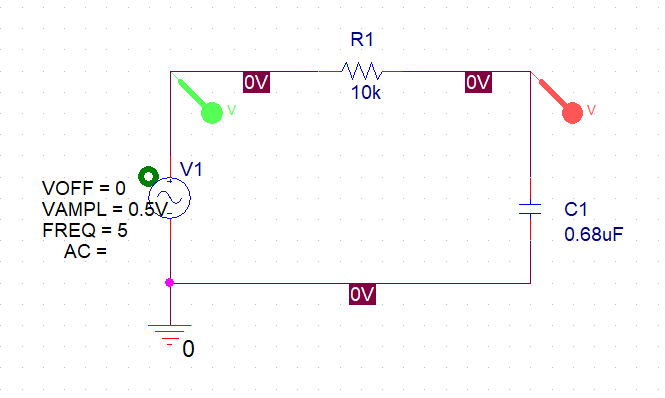
- 時域圖數據
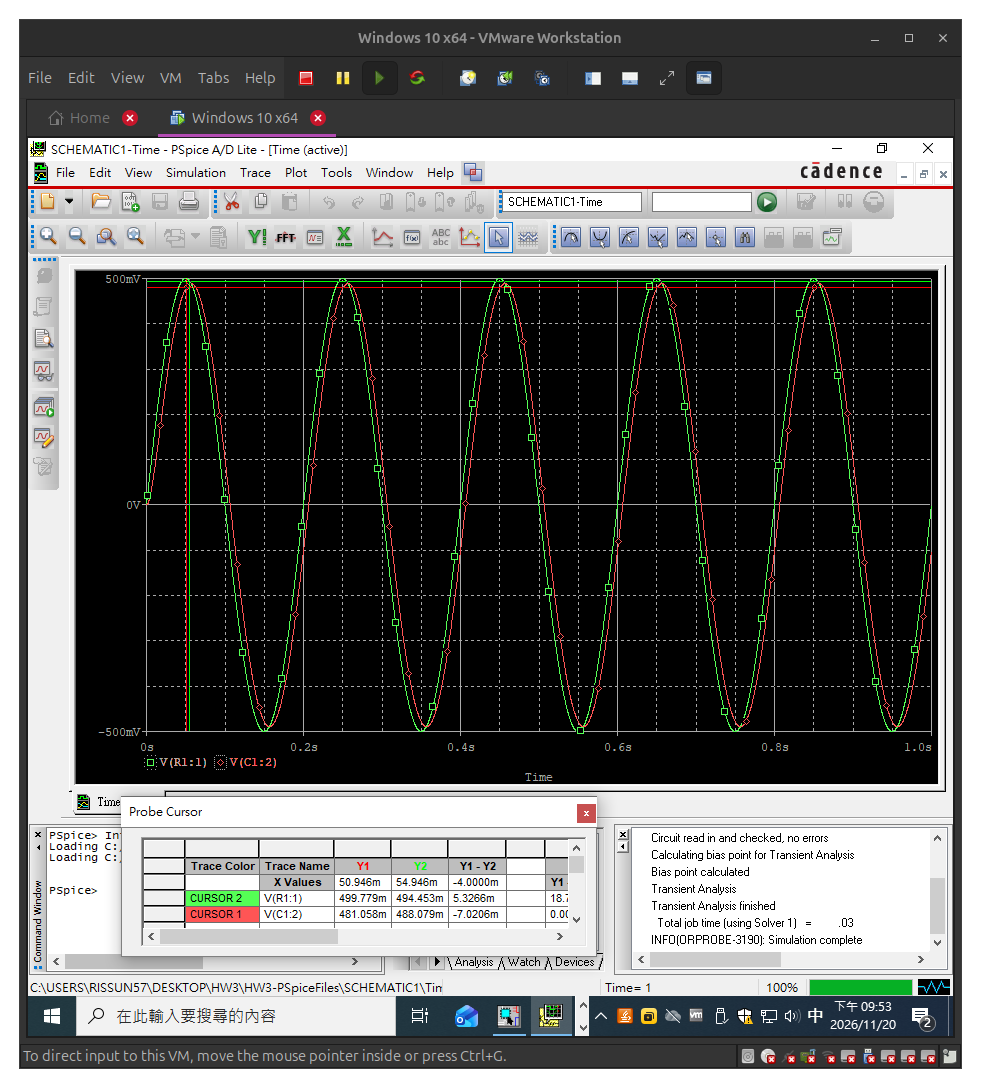
$$
 488.079/499.779 (mv)\approx 0.9765 
$$
 模擬振幅比 0.9765

- 頻域圖數據

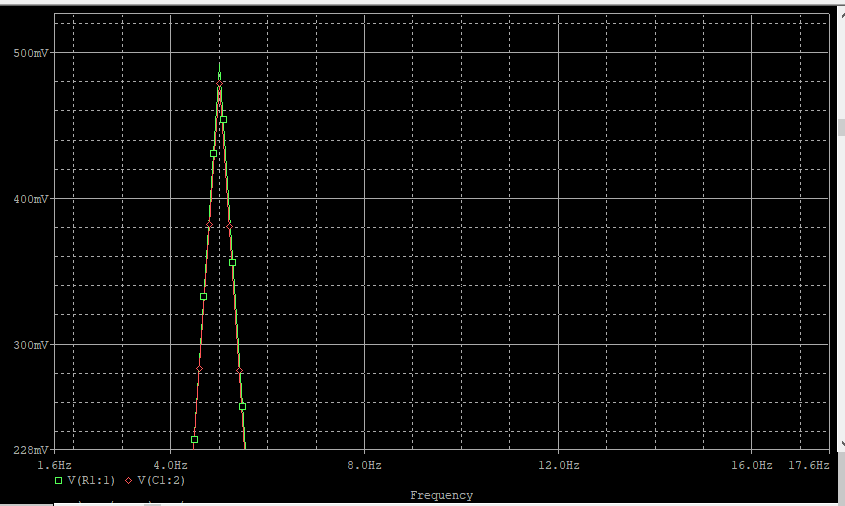

### 25Hz 
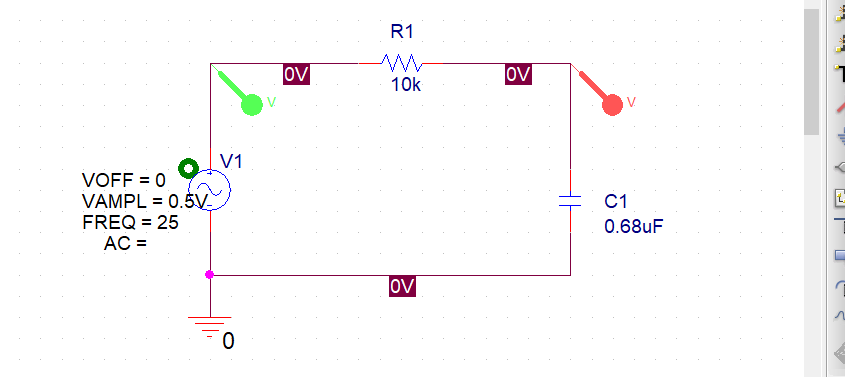

- 時域圖數據
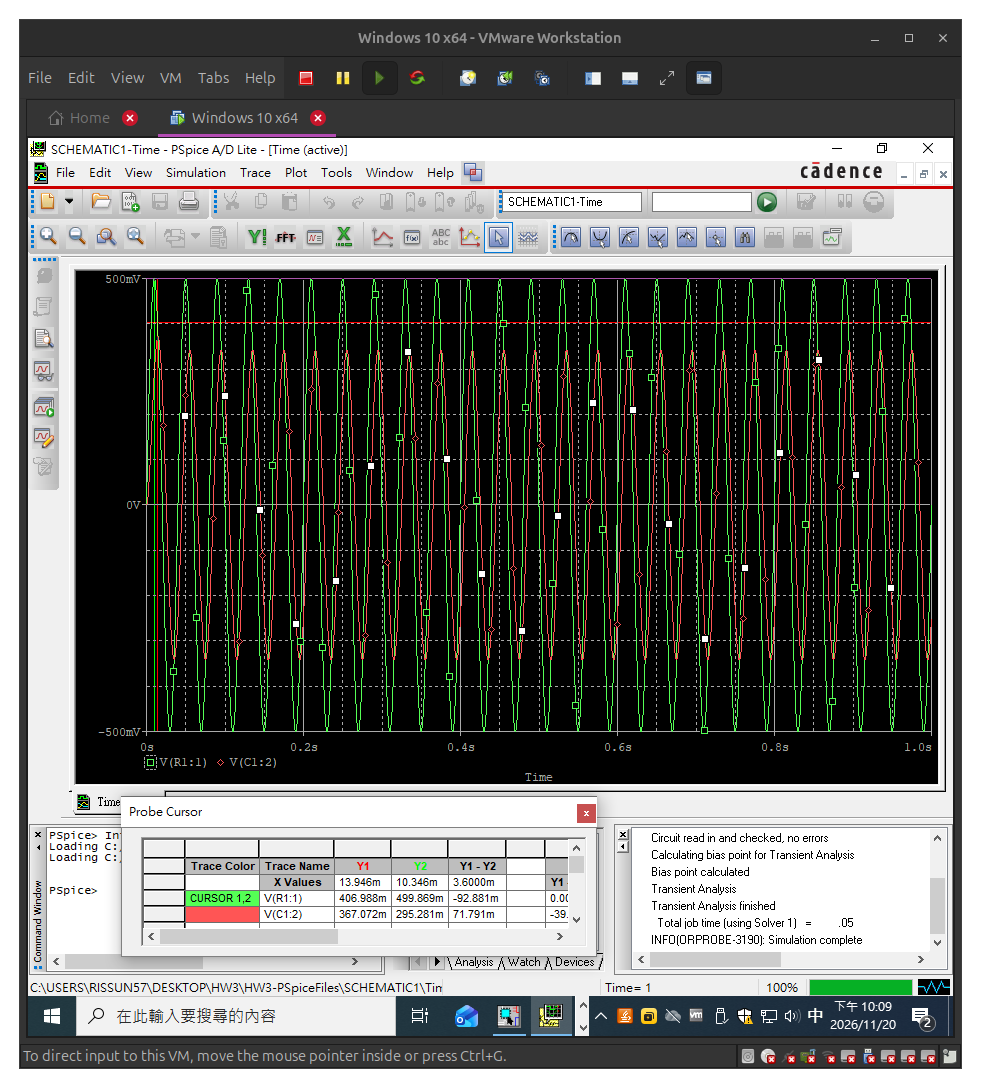
$$
 295.281/499.869 (mv)\approx 0.5907
$$
 模擬振幅比 0.5907
- 頻譜
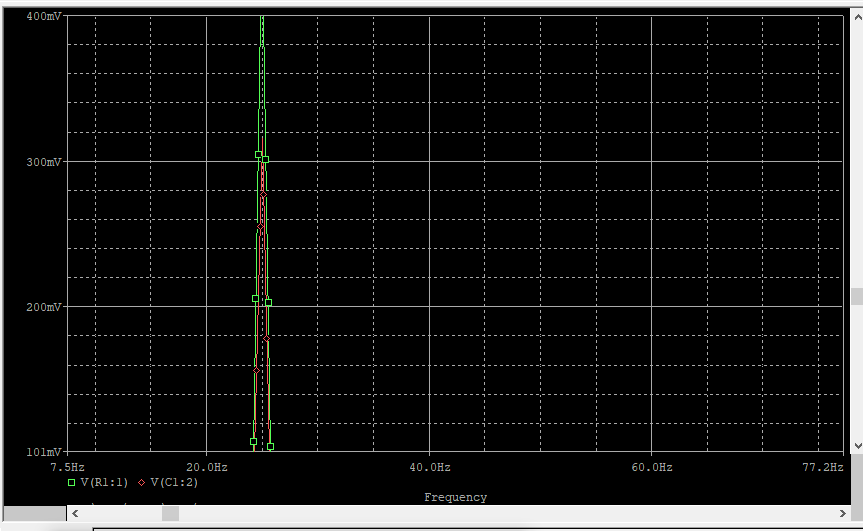
### 250Hz
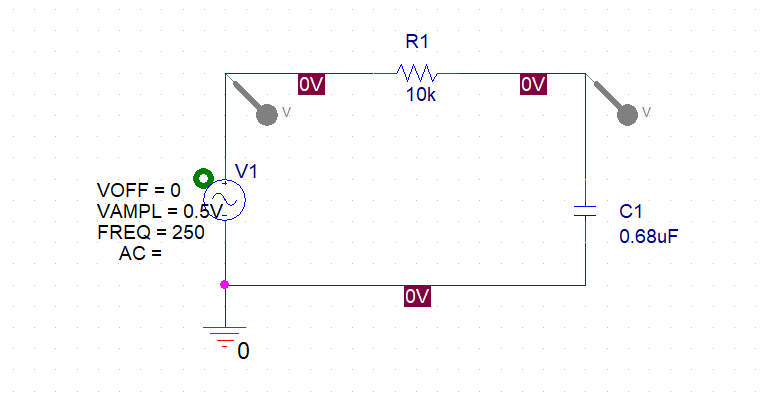
- 時域圖數據
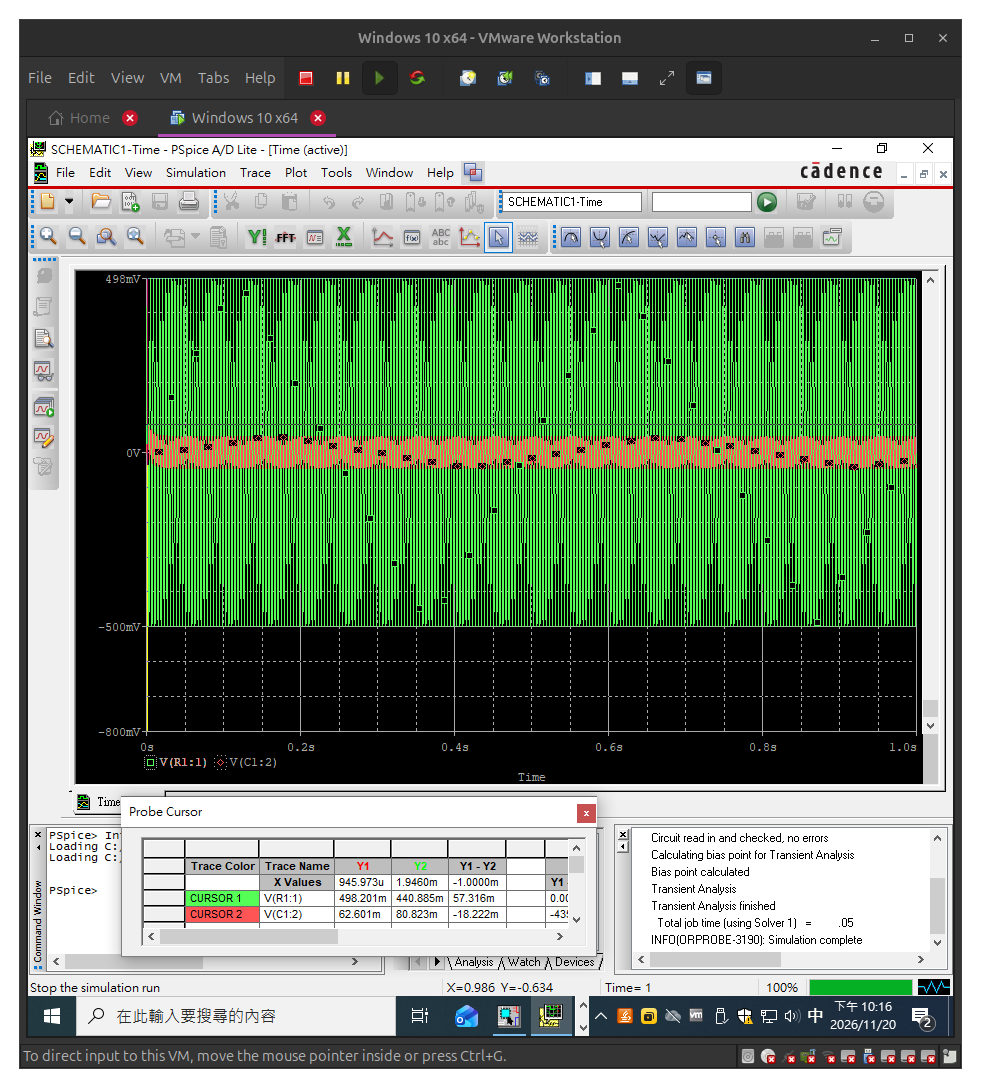
$$
 62.601/498.201 (mv)\approx 0.1256
$$
 模擬振幅比 0.1256
- 頻譜
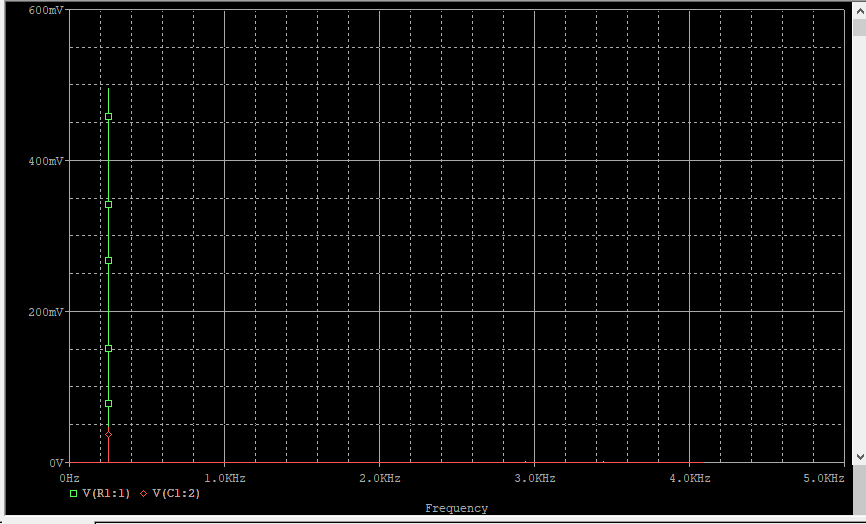

## 實作二 實體電路量測
- 依照模擬電路搭建 RC 低通濾波器，確認接線與元件數值。
- 訊號產生器輸出低壓訊號，示波器 CH1 量測 Vin、CH2 量測 Vout；兩通道接至同一接地點。
- 依序測量 5、25、250 Hz，記錄振幅比及相位差；相位可由兩波形時間差換算。
- 改用 10 Hz 方波輸入，拍攝或儲存示波器上的輸入與輸出波形。

## 思考問題
- Q1 為什麼 RC 電路對低頻和高頻的輸出振幅不同？
    - 電容的容抗大小與訊號頻率成反比，即 $\vert{}X_C\vert{} = \frac{1}{2\pi f C}$。
    - 低頻訊號（$f \ll f_c$）:  $\vert{}X_C\vert{} \gg R$，電容近似開路，因此輸出振幅幾乎等於輸入振幅（$\vert{}H(f)\vert{} \approx 1$）。
    - 高頻訊號（$f \gg f_c$）： $\vert{}X_C\vert{} \ll R$，電容近似短路，導致輸出振幅被大幅衰減。
- Q2 在截止頻率附近，輸出振幅比與相位差約為多少？
    - 輸出振幅比：$\vert{}H(f_c)\vert{} = \frac{1}{\sqrt{1 + 1^2}} = \frac{1}{\sqrt{2}} \approx \mathbf{0.707}$
    - 相位差：$\angle H(f_c) = -\arctan(1) = \mathbf{-45^\circ}$
- Q3 為什麼方波通過 RC 低通濾波器後，邊緣變得平滑？
    - RC 低通濾波器的特性是允許低頻信號通過，而衰減高頻信號
    - 構成方波邊緣的高頻諧波被濾波器大幅削弱, 就會變得平滑
- Q4 增大 R 或 C 後，截止頻率及方波響應會如何改變？
    - 分母會變大，截止頻率降低
    - 時間常數增大，電容充電/放電的速度變慢
    - 方波的上升時間和下降時間變長，邊緣變得更加圓潤
- Q5 理論、PSpice 與實測結果若有差異，可能原因有哪些？
    - 元件誤差與非理想特性，電阻和電容皆有公差，且會隨溫度/頻率變化
    - PSpice 雖然比純理論更接近真實，但是實際的模擬參數，仍會應各種原因與現實產生落差
- Q6 這個 RC 濾波器和先前 Python 聲音低通濾波實作，有哪些共同原理？
    - 兩者都是低通濾波器，目的都是保留低頻成分，衰減或移除高頻成分